# 01 - Data exploration
Raw downloads, coverage, gaps and publication lags. Every file in `data/raw` has a `.meta.json` with its source URL and query.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import pandas as pd, numpy as np
from IPython.display import Image, display
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
R = ROOT / 'results'

In [2]:
for m in sorted((ROOT/'data/raw').glob('*.meta.json')):
    j = json.loads(m.read_text()); print(f"{m.stem.replace('.meta',''):28s} rows={j['rows']:>7,}  {j.get('url','')}")

barge_grain_tons             rows= 13,240  https://agtransport.usda.gov/d/n4pw-9ygw
barge_rates                  rows=  8,344  https://agtransport.usda.gov/d/deqi-uken
export_inspections_daily     rows= 15,666  https://agtransport.usda.gov/d/sruw-w49i
export_sales_weekly          rows=  2,278  https://agtransport.usda.gov/d/wnn7-29tu
futures_zc                   rows=  6,584  https://query1.finance.yahoo.com/v8/finance/chart/ZC=F
futures_zs                   rows=  6,576  https://query1.finance.yahoo.com/v8/finance/chart/ZS=F
grain_basis_iowa             rows=  6,013  https://agtransport.usda.gov/d/v85y-3hep
nola_barge_unloads           rows=  1,097  https://agtransport.usda.gov/d/spd3-ku7f
rail_carloadings_grain       rows=  6,872  https://agtransport.usda.gov/d/tb7q-kn5i
rail_cars_by_state           rows= 45,753  https://agtransport.usda.gov/d/27k8-utc2
transport_cost_indicators    rows=  1,263  https://agtransport.usda.gov/d/8uye-ieij


In [3]:
import data_cleaning as dc
for s in dc.build_raw_weekly():
    c = s.columns[1]; lag = (s.available - s.obs_date).dt.days.median()
    print(f'{c:30s} {s.obs_date.min().date()} -> {s.obs_date.max().date()}  n={s[c].notna().sum():4d}  missing={s[c].isna().sum():3d}  median lag={lag:.0f}d')

ia_railcars                    2014-10-17 -> 2026-10-30  n= 626  missing=  3  median lag=6d
us_railcars                    2014-10-17 -> 2026-10-30  n= 619  missing= 10  median lag=6d
aar_grain_carloads             2017-03-25 -> 2026-10-31  n= 424  missing= 78  median lag=5d
barge_corn_tons                2013-01-05 -> 2026-10-31  n= 722  missing=  0  median lag=5d
barge_soy_tons                 2013-01-05 -> 2026-10-31  n= 722  missing=  0  median lag=5d
nola_unloads                   2005-10-29 -> 2026-10-31  n=1094  missing=  3  median lag=5d
insp_corn_mt                   2005-01-06 -> 2026-10-29  n=1139  missing=  0  median lag=4d
insp_soy_mt                    2005-01-06 -> 2026-10-29  n=1139  missing=  0  median lag=4d
sales_corn_exports             2005-01-06 -> 2026-10-29  n=1139  missing=  0  median lag=7d
sales_corn_net_sales           2005-01-06 -> 2026-10-29  n=1139  missing=  0  median lag=7d
sales_soy_exports              2005-01-06 -> 2026-10-29  n=1139  missing=  0  me

In [4]:
for s in ('zc','zs'):
    y = dc.futures_weekly(s); u = dc.futures_weekly_usda(s)
    print(s, 'Yahoo usable weekly returns:', round(y[y.week>='2007'].clean.mean(),3), '| USDA bad prints removed:', int(u.bad_print.sum()))

zc Yahoo usable weekly returns: 0.645 | USDA bad prints removed: 32


zs Yahoo usable weekly returns: 0.504 | USDA bad prints removed: 34


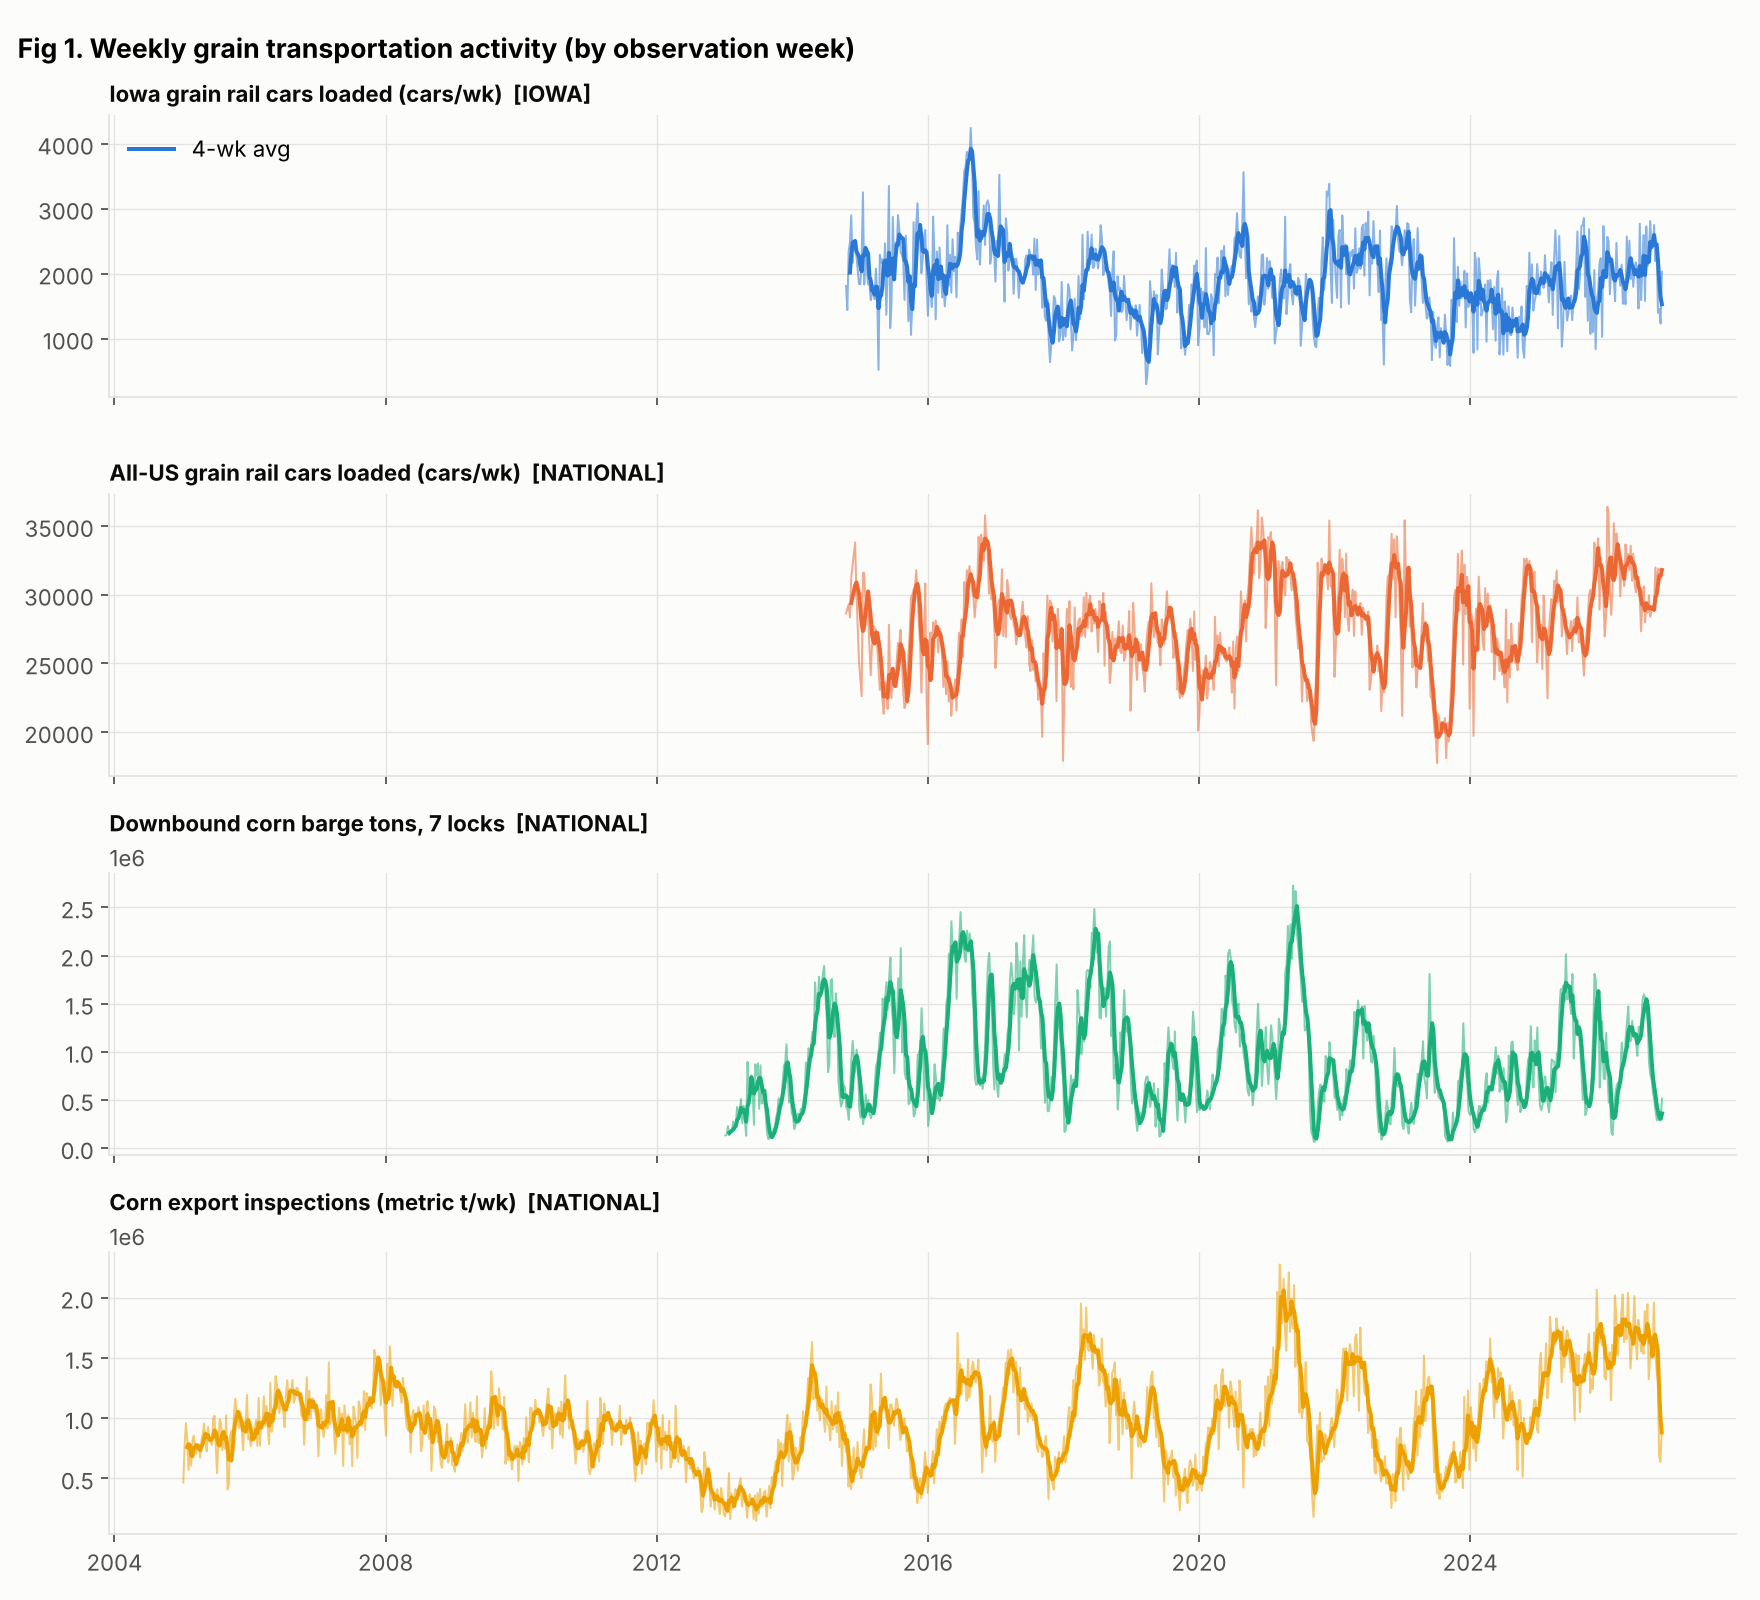

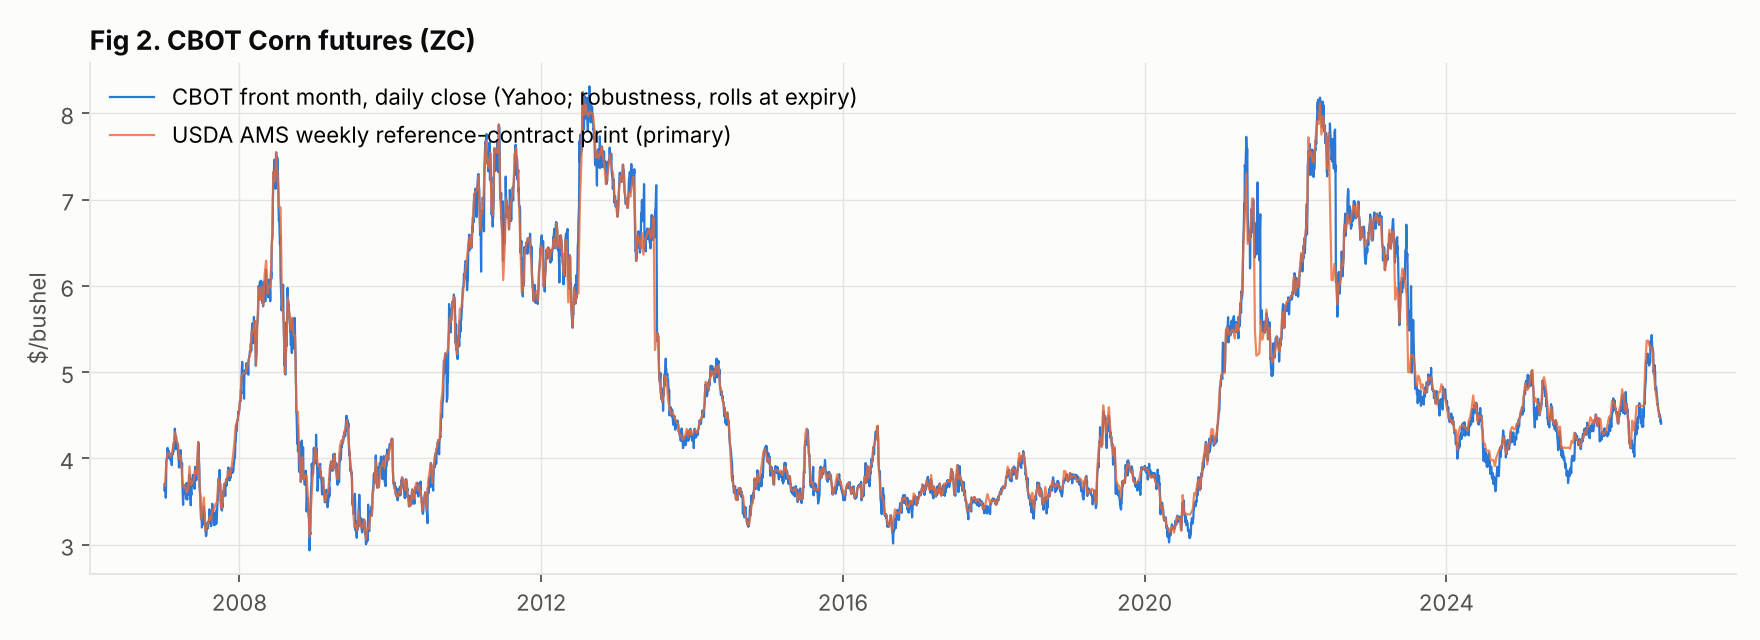

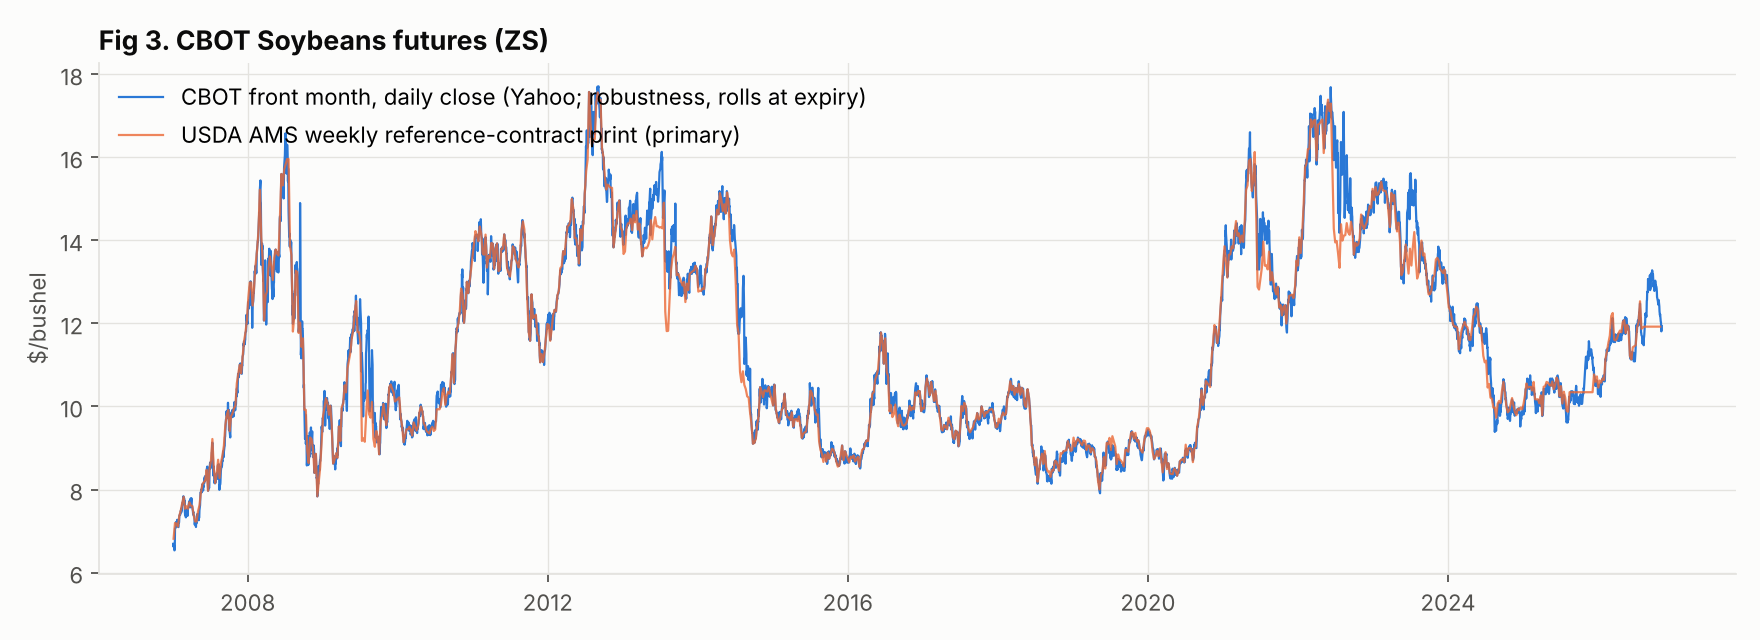

In [5]:
display(Image(R/'charts/01_transport_volumes.png'))
display(Image(R/'charts/02_corn_price.png'))
display(Image(R/'charts/03_soybeans_price.png'))